# Choosing the solver, preconditioner and log-determinant

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jejjohnson/pyrox/blob/main/docs/notebooks/gp_solver_choices.ipynb)

A `GPPrior` makes three linear-algebra choices: the solver that applies $\mathbf{A}^{-1}$, the preconditioner that speeds it up, and the log-determinant that estimates $\log \det \mathbf{A}$. The docstrings list a dozen valid combinations; this page says which one to pick for a size, a kernel and a likelihood, and what error and cost to expect. The advice comes from a benchmark, `scripts/bench_gp_solvers.py`, whose results are saved next to this notebook as `gp_solver_choices.csv`, one row per combination. Every claim below names the rows it rests on, as `likelihood-kernel-N-configuration`, and the cell after it prints them. The cells that run live use $N = 1000$ or less, so the page executes in a few minutes; the saved table goes up to $N = 8000$.

**What you'll learn:**

1. What the three choices of a `GPPrior` are, and which quantity uses each.
2. Which combination to pick for a size, a kernel and a likelihood, and what error and cost to expect.
3. How noisy the evidence gradient is, and what the preconditioner and the control variate do to that noise.
4. What a stochastic evidence means inside NUTS and SVI, and how to check whether its noise matters.

In [1]:
import subprocess
import sys


try:
    import google.colab  # noqa: F401

    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    subprocess.run(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "-q",
            "pyrox @ git+https://github.com/jejjohnson/pyrox@main#subdirectory=packages/pyrox",
            "pyrox-gp[colab] @ git+https://github.com/jejjohnson/pyrox@main#subdirectory=packages/pyrox-gp",
            "pandas",
        ],
        check=True,
    )

In [2]:
import warnings


warnings.filterwarnings("ignore", message=r".*IProgress.*")

import time
from pathlib import Path

import equinox as eqx
import gaussx as gx
import jax
import jax.numpy as jnp
import jax.random as jr
import kernellib as kl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyrox_gp as px


jax.config.update("jax_enable_x64", True)

In [3]:
import importlib.util


try:
    from IPython import get_ipython

    ipython = get_ipython()
except ImportError:
    ipython = None

if ipython is not None and importlib.util.find_spec("watermark") is not None:
    ipython.run_line_magic("load_ext", "watermark")
    ipython.run_line_magic(
        "watermark",
        "-v -m -p jax,equinox,numpyro,gaussx,kernellib,pyrox_gp,matplotlib,pandas",
    )
else:
    print("watermark extension not installed; skipping reproducibility readout.")

Python implementation: CPython
Python version       : 3.13.12
IPython version      : 9.13.0

jax       : 0.10.2
equinox   : 0.13.8
numpyro   : 0.21.0
gaussx    : 0.8.4
kernellib : 0.0.22
pyrox_gp  : 0.3.2
matplotlib: 3.10.9
pandas    : 3.0.3

Compiler    : Clang 21.1.4 
OS          : Linux
Release     : 6.8.0-1044-azure
Machine     : x86_64
Processor   : x86_64
CPU cores   : 16
Architecture: 64bit



## 1. The three choices

With $N$ training points, the kernel matrix $\mathbf{K}_{XX} \in \mathbb{R}^{N \times N}$ (jitter included) and the noise or site variances $\mathbf{d} \in \mathbb{R}^N$, every quantity of a GP solves against one system,

$$\mathbf{A} = \mathbf{K}_{XX} + \mathrm{diag}(\mathbf{d}) \in \mathbb{R}^{N \times N}.$$

For Gaussian noise $\mathbf{d} = \sigma^2 \mathbf{1}$; inside a Laplace fit $d_n = 1 / \lambda_n$, the inverse site precision of point $n$, and $\mathbf{A}$ changes at every Newton step. The Gaussian evidence, with $\mathbf{r} = \mathbf{y} - \boldsymbol{\mu}_f \in \mathbb{R}^N$ the residual of the prior mean, uses both maps:

$$\log p(\mathbf{y}) = -\tfrac12 \mathbf{r}^\top \mathbf{A}^{-1} \mathbf{r} - \tfrac12 \log \det \mathbf{A} - \tfrac{N}{2} \log 2 \pi.$$

| Choice | `GPPrior` field | Computes | Shape | Used by |
| --- | --- | --- | --- | --- |
| solver | `solver` | $\mathbf{A}^{-1} \mathbf{b}$ | $\mathbf{b} \in \mathbb{R}^N$, or $N \times M$ for $M$ test points | the quadratic term, `condition` and `predict`, every Newton step |
| preconditioner | `preconditioner` | $\mathbf{P}^{-1} \mathbf{v}$ inside CG, $\mathbf{P} \approx \mathbf{A}$ of rank $R$ plus $\mathrm{diag}(\mathbf{d})$ | $\mathbf{U} \in \mathbb{R}^{N \times R}$ | the number of CG steps, and the variance of a stochastic log-determinant |
| log-determinant | `logdet` | $\log \det \mathbf{A}$ | scalar | the evidence (`log_marginal`, `gp_factor`, the Laplace evidence) and its gradient |

A dense solver factorises $\mathbf{A}$ once, at $O(N^3)$ time and $O(N^2)$ memory, and gives both maps exactly. An iterative one never forms $\mathbf{K}_{XX}$ (`GPPrior(..., matrix_free=True)` evaluates it block by block in each product) and estimates the log-determinant by stochastic Lanczos quadrature (SLQ) over $N_\text{probe}$ random probes $\mathbf{z}^{(i)} \in \mathbb{R}^N$, with $\mathbf{T}^{(i)}$ the Lanczos tridiagonal of probe $i$:

$$\log \det \mathbf{A} \approx \frac{1}{N_\text{probe}} \sum_{i=1}^{N_\text{probe}} \Vert \mathbf{z}^{(i)} \Vert_2^2 \, \mathbf{e}_1^\top \log(\mathbf{T}^{(i)}) \mathbf{e}_1.$$

With a preconditioner the estimate splits as $\log \det \mathbf{A} = \log \det \mathbf{P} + \log \det(\mathbf{P}^{-1/2} \mathbf{A} \mathbf{P}^{-1/2})$, the first term exact and the second near zero, so its probe noise is smaller. The benchmark compares these configurations, all on `matrix_free=True` except `dense`, and all built with `throw=False` so a solve that misses its tolerance is reported rather than raised:

| Name | Solver | Preconditioner | Log-determinant |
| --- | --- | --- | --- |
| `dense` | `DenseSolver` (Cholesky) | none | exact |
| `cg` | `CGSolver(rtol=1e-4)` | none | CG's own SLQ, 20 probes, 30 Lanczos steps |
| `cg-nystrom` | `CGSolver(rtol=1e-4)` | `NystromPreconditioner.lazy(200)` | `SLQLogdet(num_probes=50)`, preconditioned, gradient with the control variate of [gaussx#826](https://github.com/jejjohnson/gaussx/issues/826) |
| `cg-nystrom-fixedP` | `CGSolver(rtol=1e-4)` | the same Nyström, built once at the evaluation point | the same SLQ; $\mathbf{P}$ has no gradient, so the control variate adds nothing |
| `matfree` | `px.matfree_solver(rank=200)` | Nyström, rebuilt from $\mathbf{A}$ | `NystromLogdet`: exact $\log \det \mathbf{P}$ plus SLQ of the remainder, 50 probes, 30 steps |
| `matfree-fitc`, `matfree-r50`, `matfree-r800`, `matfree-lanczos60` | `matfree_solver` with `preconditioner="fitc"`, rank 50, rank 800, or 60 Lanczos steps | | |
| `bbmm` | `px.bbmm_solver(rank=200)` | lazy Nyström | BBMM's shared pass, 50 probes drawn from $\mathbf{P}$, gradient with the control variate |

The two presets are one call each and return an ordinary gaussx strategy, as the cell below shows.

In [4]:
key = jr.key(0)

dense = None  # GPPrior(solver=None): gaussx.DenseSolver, a Cholesky of A

# the three fields, set one by one
solver = gx.CGSolver(rtol=1e-4)
preconditioner = gx.NystromPreconditioner.lazy(200, key=key)
logdet = gx.SLQLogdet(num_probes=50)
composed = gx.compose_solver(solver, preconditioner=preconditioner, logdet=logdet)

# or one preset call each, with the same three parts inside
matfree = px.matfree_solver(rank=200, key=key)
bbmm = px.bbmm_solver(rank=200, key=key)

for name, strategy in [
    ("CG + Nyström + SLQ", composed),
    ("matfree_solver", matfree),
    ("bbmm_solver", bbmm),
]:
    print(f"{name:20s} -> {type(strategy).__name__}")

CG + Nyström + SLQ   -> ComposedSolver
matfree_solver       -> ComposedSolver
bbmm_solver          -> KeyedSolver


## The saved results

The benchmark draws $N$ inputs uniformly on the unit square, sets the latent function to $f(\mathbf{x}) = \sin(6 x_1) + \cos(4 x_2)$, and observes it with Gaussian noise of variance $\sigma^2 = 0.01$ or as Bernoulli labels with probability $\mathrm{sigmoid}(2 f)$. The kernel is a Matérn-3/2 of unit variance with a smooth ($\ell = 0.3$) or a rough ($\ell = 0.03$) lengthscale, and each evidence is evaluated at those hyperparameters. The sizes are $N \in \{500, 2000\}$ for both likelihoods and $N = 8000$ for the Gaussian one, with three keys per stochastic configuration below 8000 and one at 8000. The run had to fit a shared VM (it took about 46 minutes), so 8000 is the largest size, the Bernoulli likelihood stops at 2000, and the rough kernel at 8000 has `dense` and `matfree` only. The dense reference is exact at every size measured, so every error is against it; at $N = 8000$, with one key, the RMS error is the error of that key.

The timings are on the CPU of the VM, four cores (`taskset -c 0-3`), in float64, after ahead-of-time compilation, with `jax.block_until_ready`, and the median over the keys. There is no GPU on the VM, so no row is a GPU timing. `passes_evidence` counts the calls of the kernel operator's matvec in one evidence: each call evaluates $\mathbf{K}_{XX}$ once, block by block, and applies it to one vector or to a batch of probes, so it is the unit of cost of a matrix-free GP. `mem_evidence_mb` and `mem_grad_mb` are XLA's temporary allocation of the compiled executable. `logz_bias`, `logz_std` and `logz_rms` are in nats against the dense evidence, with $\mathrm{RMS}^2 = \mathrm{bias}^2 + \mathrm{var}$ over the keys, and `grad_rel_rms_*` is the RMS error of each component of the gradient over the keys, divided by the dense component. The effective dimension

$$d_\text{eff} = \mathrm{tr}\big(\mathbf{K}_{XX} \mathbf{A}^{-1}\big) \in [0, N]$$

counts the eigen-directions of $\mathbf{K}_{XX}$ that stand above the noise; it is what a preconditioner's rank has to cover, and the cell below prints it for each data set.

In [5]:
# next to this notebook (or from the repository root); on Colab, from GitHub
CSV = "gp_solver_choices.csv"
local = [path for path in (Path(CSV), Path("docs/notebooks") / CSV) if path.is_file()]
URL = f"https://raw.githubusercontent.com/jejjohnson/pyrox/main/docs/notebooks/{CSV}"
results = pd.read_csv(local[0] if local else URL).set_index("id")


def cite(*ids: str, columns: tuple[str, ...] | None = None) -> pd.DataFrame:
    """The saved rows a claim on this page rests on."""
    cols = columns or (
        "logz_rel_rms",
        "logz_bias",
        "logz_std",
        "grad_rel_rms_max",
        "pred_mean_rel_err",
        "t_evidence_s",
        "t_grad_s",
        "passes_evidence",
        "mem_evidence_mb",
    )
    return results.loc[list(ids), list(cols)]


print(
    f"{len(results)} rows: N in {sorted(results.n.unique().tolist())}, device {results.device.iloc[0]}"
)
results.groupby(["likelihood", "kernel", "n"]).d_eff.first().dropna().round(
    1
).to_frame()

53 rows: N in [500, 2000, 8000], device cpu:x86_64


d_eff
likelihood kernel n           
bernoulli  rough  500     79.3
                  2000   220.6
           smooth 500     14.9
                  2000    26.8
gaussian   rough  500    480.9
                  2000  1777.9
                  8000  5572.1
           smooth 500    183.2
                  2000   355.4
                  8000   644.4

## 2. The decision table

What to use, filled from the saved rows. "Larger" means beyond the sizes measured here: on this CPU the dense solver gave the fastest evidence at every size up to $N = 8000$, so the iterative rows are for a problem whose dense factor no longer fits in memory.

| Situation | Solver | Preconditioner | Log-determinant |
| --- | --- | --- | --- |
| $N \le 8000$ (the largest measured), memory permitting | `DenseSolver` (the default) | none | dense |
| larger, Gaussian noise, smooth kernel | `bbmm_solver` for training (the cheapest gradient and memory), `matfree_solver` for single evidences | Nyström, rank $R \gtrsim 2 d_\text{eff}$ | BBMM's shared pass, or `NystromLogdet` |
| larger, non-Gaussian | the same, on `LaplaceInference` | Nyström, scaled per point by the presets; rank 200 gave 0.010 nats at $d_\text{eff} = 27$ and 0.47 to 0.78 nats at $d_\text{eff} = 221$ | the same |
| very rough kernel ($d_\text{eff}$ near $N$) | dense, or inducing points | none | dense |
| NUTS | dense, or a preset with a fixed key whose `logz_std` is well below one nat | as above | as above |

The rows behind each line, in order:

- Dense is the fastest evidence at every size: 3.64 s at $N = 8000$ on the smooth kernel against 25.0 s for `matfree` and 40.7 s for `bbmm`, and its gradient (47.7 s) is level with `bbmm`'s (48.3 s) and half of `matfree`'s (88.7 s); the price is memory, 4.9 GB of temporaries for the dense gradient against 742 MB for `bbmm` (rows `gaussian-smooth-8000-dense`, `-matfree`, `-bbmm`).
- On the smooth kernel `bbmm` has the cheaper gradient of the two presets at every size, and at every size the smaller gradient memory (113 MB against 1028 MB for `matfree` at $N = 2000$, rows `gaussian-smooth-2000-bbmm`, `-matfree`), and `matfree` the cheaper evidence at $N = 8000$ (25.0 against 40.7 s).
- The rank: on the smooth kernel at $N = 2000$, $d_\text{eff} = 355$, and only rank 800 brings the evidence error from 1.3 to 0.18 nats (rows `gaussian-smooth-2000-dense`, `-matfree`, `-matfree-r800`).
- Non-Gaussian: the Laplace evidence errors of the presets at $N = 2000$ are 0.010 to 0.011 nats on the smooth kernel and 0.47 to 0.78 nats on the rough one (rows `bernoulli-*-2000-matfree`, `-bbmm`, `bernoulli-*-2000-dense` for $d_\text{eff}$).
- Rough: $d_\text{eff} = 1778$ of 2000 and 5572 of 8000, an evidence error of 6.6 to 9.9 nats for every preconditioned configuration at 2000 and 78 nats for `matfree` at 8000, which also takes 85.7 s against 3.8 s dense (rows `gaussian-rough-2000-*`, `gaussian-rough-8000-dense`, `-matfree`).
- NUTS: see section 6.

In [6]:
cite(
    "gaussian-smooth-8000-dense",
    "gaussian-smooth-8000-matfree",
    "gaussian-smooth-8000-bbmm",
    "gaussian-smooth-2000-dense",
    "gaussian-smooth-2000-matfree",
    "gaussian-smooth-2000-bbmm",
    "gaussian-smooth-2000-matfree-r800",
    "bernoulli-smooth-2000-matfree",
    "bernoulli-smooth-2000-bbmm",
    "bernoulli-rough-2000-matfree",
    "bernoulli-rough-2000-bbmm",
    "gaussian-rough-2000-matfree",
    "gaussian-rough-8000-dense",
    "gaussian-rough-8000-matfree",
    columns=(
        "logz_rms",
        "logz_std",
        "t_evidence_s",
        "t_grad_s",
        "mem_grad_mb",
        "passes_evidence",
    ),
)

,logz_rms,logz_std,t_evidence_s,t_grad_s,mem_grad_mb,passes_evidence
id,,,,,,
gaussian-smooth-8000-dense,0.000000,0.000000,3.642571,47.690783,4882.873734,NaN
gaussian-smooth-8000-matfree,2.045636,0.000000,25.027743,88.732183,4370.463844,70.0
gaussian-smooth-8000-bbmm,2.624220,0.000000,40.723622,48.283848,742.487617,95.0
gaussian-smooth-2000-dense,0.000000,0.000000,0.127175,1.223898,274.673721,NaN
gaussian-smooth-2000-matfree,1.300294,1.376287,1.711607,5.224063,1027.604713,55.0
gaussian-smooth-2000-bbmm,0.783163,0.511604,1.987819,2.554227,113.445747,54.0
gaussian-smooth-2000-matfree-r800,0.176620,0.093654,3.948382,9.161701,1158.179359,40.0
bernoulli-smooth-2000-matfree,0.010287,0.012031,3.021011,7.075336,1127.378609,87.0
bernoulli-smooth-2000-bbmm,0.010793,0.012709,2.587076,3.867194,140.269783,63.0


## 3. The Gaussian GP

The same Matérn-3/2 problem at $N = 1000$, smooth kernel, run live: the dense reference, unpreconditioned CG and the two presets, each compiled once and then timed. The error columns compare the log marginal and the predictive mean and variance at 64 test points with the dense ones. These numbers illustrate the code; the claims below rest on the saved rows, which use three keys and more sizes.

In [7]:
N = 1000
NOISE_VAR = 0.01
X = jr.uniform(jr.key(0), (N, 2))
X_star = jr.uniform(jr.key(1), (64, 2))
f_true = jnp.sin(6.0 * X[:, 0]) + jnp.cos(4.0 * X[:, 1])
y = f_true + jnp.sqrt(NOISE_VAR) * jr.normal(jr.key(2), (N,))
labels = jr.bernoulli(jr.key(2), jax.nn.sigmoid(2.0 * f_true)).astype(X.dtype)
kernel = kl.Matern(nu=1.5, lengthscale=0.3, variance=1.0)


def compiled_and_timed(fn, *args, repeats=3):
    """Compile ``fn``, then return its output and the median time of a call."""
    out = jax.block_until_ready(fn(*args))
    times = []
    for _ in range(repeats):
        start = time.perf_counter()
        jax.block_until_ready(fn(*args))
        times.append(time.perf_counter() - start)
    return out, float(np.median(times))


@eqx.filter_jit
def gaussian(solver, matrix_free):
    prior = px.GPPrior(kernel, X, solver=solver, matrix_free=matrix_free)
    log_marginal = prior.log_marginal(y, jnp.asarray(NOISE_VAR))
    mean, var = prior.condition(y, jnp.asarray(NOISE_VAR)).predict(X_star)
    return log_marginal, mean, var


live = {
    "dense": (None, False),
    "cg": (gx.CGSolver(rtol=1e-4, throw=False), True),
    "matfree": (px.matfree_solver(rank=200, key=key, throw=False), True),
    "bbmm": (px.bbmm_solver(rank=200, key=key, throw=False), True),
}
rows = {}
for name, (strategy, matrix_free) in live.items():
    rows[name] = compiled_and_timed(gaussian, strategy, matrix_free)
(ref_logz, ref_mean, ref_var), _ = rows["dense"]
pd.DataFrame(
    {
        name: {
            "log marginal": float(logz),
            "error (nats)": float(logz - ref_logz),
            "mean rel. error": float(
                jnp.linalg.norm(mean - ref_mean) / jnp.linalg.norm(ref_mean)
            ),
            "variance rel. error": float(
                jnp.linalg.norm(var - ref_var) / jnp.linalg.norm(ref_var)
            ),
            "time (s)": seconds,
        }
        for name, ((logz, mean, var), seconds) in rows.items()
    }
).T

,log marginal,error (nats),mean rel. error,variance rel. error,time (s)
dense,681.991574,0.000000,0.000000e+00,0.000000e+00,0.073596
cg,670.202437,-11.789137,5.745421e-06,1.036506e-03,2.158684
matfree,681.311979,-0.679595,1.006554e-07,4.561568e-09,0.895724
bbmm,679.832710,-2.158863,3.360913e-06,3.544366e-07,0.726481


The saved rows extend this to $N = 2000$ and $8000$ and to the rough kernel. Four things stand out.

- **Time.** The dense evidence is the fastest at every size: 0.13 s at $N = 2000$ and 3.6 s at $N = 8000$ on the smooth kernel, against 1.7 s and 25.0 s for `matfree` and 2.0 s and 40.7 s for `bbmm` (rows `gaussian-smooth-2000-*`, `gaussian-smooth-8000-*`). For the gradient the gap closes: at $N = 8000$ dense takes 47.7 s, `bbmm` 48.3 s and `matfree` 88.7 s.
- **Memory.** XLA's temporary allocation for the dense gradient grows from 275 MB at $N = 2000$ to 4.9 GB at $N = 8000$, while `bbmm` needs 113 MB and 742 MB; the `matfree` gradient is the large one among the presets, 1.0 GB and 4.4 GB (same rows).
- **Error.** On the smooth kernel the presets' RMS evidence error is 1.3 nats (`matfree`) and 0.78 nats (`bbmm`) at $N = 2000$ over three keys, and 2.0 and 2.6 nats at $N = 8000$ with one key, a relative error of $3 \cdot 10^{-4}$ to $4 \cdot 10^{-4}$. Unpreconditioned `cg` is at 26.7 nats on the same problem at $N = 2000$, with 370 kernel passes against 55 for `matfree` (row `gaussian-smooth-2000-cg`). The predictions are accurate everywhere: the relative error of the predictive mean is at most $2.5 \cdot 10^{-5}$ in every row (largest in `gaussian-rough-2000-bbmm`) and of the predictive variance at most $1.6 \cdot 10^{-3}$ (`gaussian-smooth-2000-cg`), so the evidence's error comes from the log-determinant, not from the solves.
- **The rough kernel.** With $d_\text{eff} = 1778$ of 2000 points, every iterative configuration is off by 6.6 to 22 nats at $N = 2000$, and `bbmm` needs 431 kernel passes and 11.0 s per evidence (rows `gaussian-rough-2000-*`); at $N = 8000$ `matfree` is 78 nats off and takes 85.7 s (row `gaussian-rough-8000-matfree`).

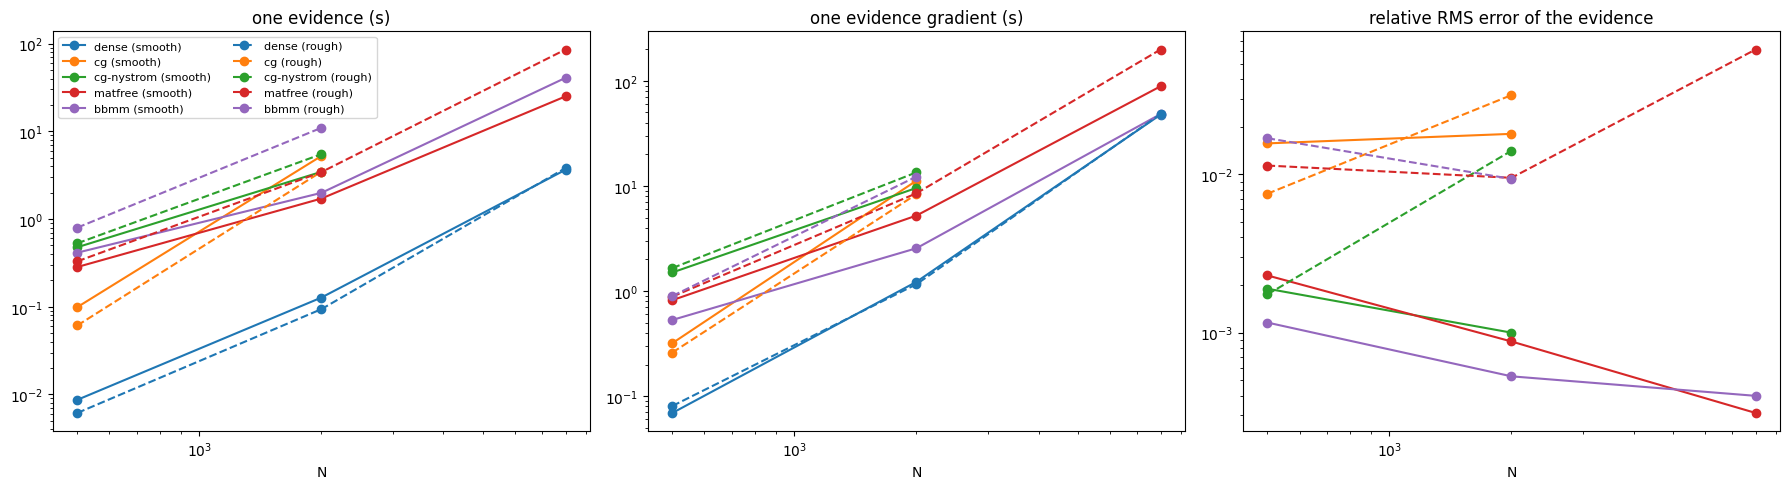

In [8]:
def scaling_plot(likelihood):
    _, axes = plt.subplots(1, 3, figsize=(18, 5))
    for kernel_name, style in [("smooth", "-"), ("rough", "--")]:
        part = results[
            (results.likelihood == likelihood) & (results.kernel == kernel_name)
        ]
        for i, config in enumerate(["dense", "cg", "cg-nystrom", "matfree", "bbmm"]):
            rows = part[part.config == config].sort_values("n")
            if rows.empty:
                continue
            label = f"{config} ({kernel_name})"
            axes[0].loglog(
                rows.n, rows.t_evidence_s, style, marker="o", color=f"C{i}", label=label
            )
            axes[1].loglog(
                rows.n, rows.t_grad_s, style, marker="o", color=f"C{i}", label=label
            )
            if config != "dense":
                axes[2].loglog(
                    rows.n,
                    rows.logz_rel_rms,
                    style,
                    marker="o",
                    color=f"C{i}",
                    label=label,
                )
    axes[0].set_title(
        "one evidence (s)" if likelihood == "gaussian" else "one Laplace fit (s)"
    )
    axes[1].set_title("one evidence gradient (s)")
    axes[2].set_title("relative RMS error of the evidence")
    for ax in axes:
        ax.set_xlabel("N")
    axes[0].legend(fontsize=8, ncol=2)
    plt.tight_layout()
    plt.show()


scaling_plot("gaussian")

In [9]:
gauss_ids = [
    f"gaussian-{k}-{n}-{c}"
    for k in ("smooth", "rough")
    for n in (500, 2000, 8000)
    for c in ("dense", "cg", "cg-nystrom", "matfree", "bbmm", "matfree-fitc")
]
cite(
    *[i for i in gauss_ids if i in results.index],
    columns=(
        "logz_rel_rms",
        "logz_bias",
        "logz_std",
        "pred_mean_rel_err",
        "pred_var_rel_err",
        "t_evidence_s",
        "t_grad_s",
        "passes_evidence",
        "mem_evidence_mb",
        "mem_grad_mb",
    ),
)

,logz_rel_rms,logz_bias,logz_std,pred_mean_rel_err,pred_var_rel_err,t_evidence_s,t_grad_s,passes_evidence,mem_evidence_mb,mem_grad_mb
id,,,,,,,,,,
gaussian-smooth-500-dense,0.000000,0.000000,0.000000,0.000000e+00,0.000000e+00,0.008672,0.069202,NaN,3.822403,17.170181
gaussian-smooth-500-cg,0.015681,-1.253754,5.367077,5.492198e-06,7.109396e-04,0.098934,0.319205,216.0,7.302650,104.286156
gaussian-smooth-500-cg-nystrom,0.001892,-0.117973,0.657944,1.240554e-07,3.957171e-10,0.476784,1.502459,46.0,18.561707,267.888367
gaussian-smooth-500-matfree,0.002295,-0.158015,0.793874,1.410367e-07,4.937309e-10,0.283603,0.818765,45.0,16.383362,278.635536
gaussian-smooth-500-bbmm,0.001156,0.035945,0.409322,1.639487e-07,1.773665e-08,0.413299,0.530817,32.0,14.976562,34.846375
gaussian-smooth-2000-dense,0.000000,0.000000,0.000000,0.000000e+00,0.000000e+00,0.127175,1.223898,NaN,61.065689,274.673721
gaussian-smooth-2000-cg,0.018012,-22.853263,16.856047,4.390139e-06,1.605033e-03,5.234948,11.236667,370.0,21.436691,408.224571
gaussian-smooth-2000-cg-nystrom,0.000998,0.549815,1.680785,2.154715e-07,2.595635e-08,3.452868,9.571566,56.0,90.620125,1021.065430
gaussian-smooth-2000-matfree,0.000878,0.654207,1.376287,8.592607e-08,2.113287e-08,1.711607,5.224063,55.0,79.846992,1027.604713


## 4. The Bernoulli Laplace fit

The Bernoulli labels on the same inputs, fitted by `LaplaceInference`. The strategy takes the solver from the prior, so the presets go on `GPPrior` as before; inside the fit $\mathbf{d}$ is the vector of inverse site precisions, which the presets read from the system at every Newton step. The tolerance of the Newton loop is $10^{-3}$, ten times looser than the CG tolerance, as the `LaplaceInference` docstring asks for an iterative solver.

In [10]:
strategy = px.LaplaceInference(tol=1e-3)


@eqx.filter_jit
def laplace(solver, matrix_free):
    prior = px.GPPrior(kernel, X, solver=solver, matrix_free=matrix_free)
    fit = strategy.fit(prior, px.BernoulliLikelihood(), labels)
    return fit.log_marginal_approx, fit.predict_mean(X_star), fit.n_iter


rows = {}
for name in ["dense", "matfree", "bbmm"]:
    rows[name] = compiled_and_timed(laplace, *live[name])
(ref_logz, ref_mean, _), _ = rows["dense"]
pd.DataFrame(
    {
        name: {
            "Laplace evidence": float(logz),
            "error (nats)": float(logz - ref_logz),
            "mean rel. error": float(
                jnp.linalg.norm(mean - ref_mean) / jnp.linalg.norm(ref_mean)
            ),
            "Newton steps": int(n_iter),
            "time of the fit (s)": seconds,
        }
        for name, ((logz, mean, n_iter), seconds) in rows.items()
    }
).T

,Laplace evidence,error (nats),mean rel. error,Newton steps,time of the fit (s)
dense,-455.816165,0.000000,0.000000e+00,5.0,0.247158
matfree,-455.811972,0.004193,1.232152e-08,5.0,1.442248
bbmm,-455.818484,-0.002319,1.319668e-08,5.0,1.359350


The Laplace system is much better conditioned than the Gaussian one: a Bernoulli site has $\lambda_n = p_n (1 - p_n) \le 1/4$, so $d_n \ge 4$, against $\sigma^2 = 0.01$ for the Gaussian noise. The effective dimension drops accordingly, to 26.8 on the smooth kernel and 220.6 on the rough one at $N = 2000$ (rows `bernoulli-smooth-2000-dense`, `bernoulli-rough-2000-dense`, against 355 and 1778 for the Gaussian rows), and the errors of the presets drop with it. On the smooth kernel the RMS error of the Laplace evidence at $N = 2000$ is 0.010 nats for `matfree` and 0.011 nats for `bbmm`, against 1.41 nats for unpreconditioned `cg` (rows `bernoulli-smooth-2000-matfree`, `-bbmm`, `-cg`); on the rough kernel the presets are at 0.78 and 0.47 nats and `cg` at 2.95 (rows `bernoulli-rough-2000-*`). The dense fit is still the fastest at this size: 1.06 s for the whole fit against 3.02 s and 2.59 s for the presets on the smooth kernel, and 0.87 s against 3.21 s and 2.87 s on the rough one. The gradient follows the same order, with `bbmm` the cheapest iterative one (3.87 s against 4.67 s dense on the smooth kernel), and the unpreconditioned `cg` gradient is the outlier, 60 % off in its lengthscale component on the smooth kernel (row `bernoulli-smooth-2000-cg`).

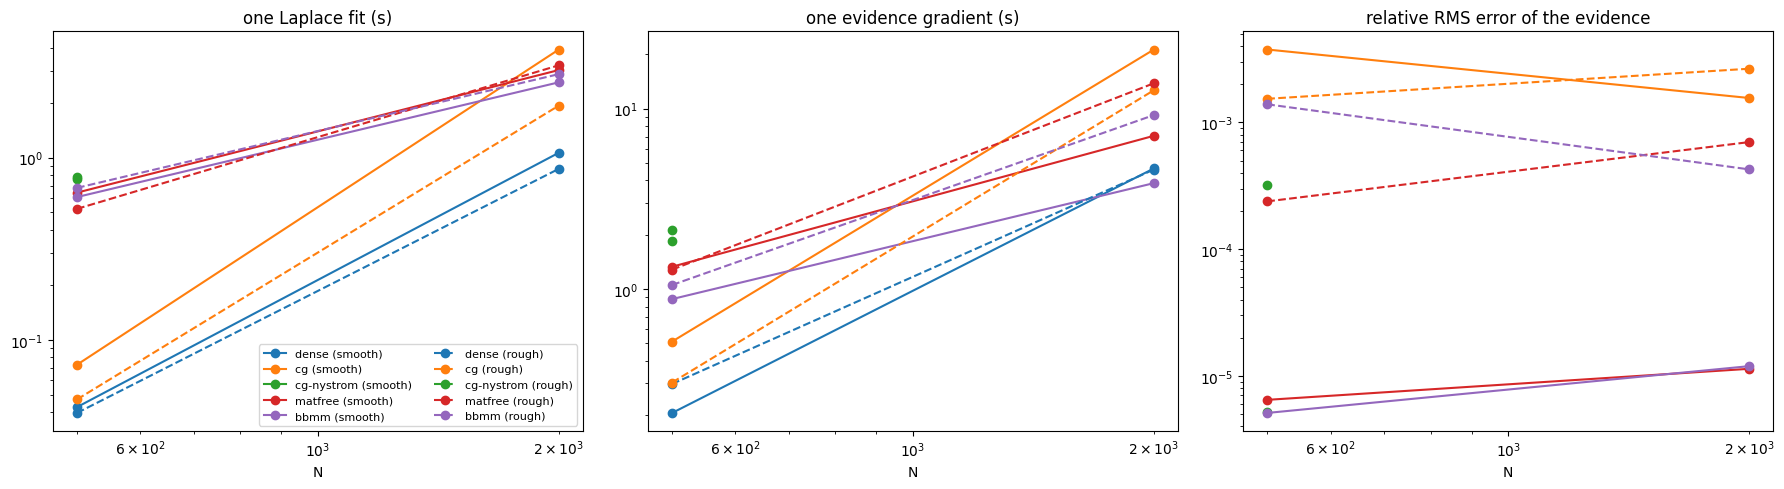

,logz_rel_rms,logz_bias,grad_rel_rms_max,pred_mean_rel_err,t_evidence_s,t_grad_s,passes_evidence,newton_iters,d_eff
id,,,,,,,,,
bernoulli-smooth-500-dense,0.000000,0.000000,0.000000,0.000000e+00,0.042726,0.205825,NaN,5.0,14.926274
bernoulli-smooth-500-cg,0.003760,0.559731,0.144306,7.889830e-07,0.072994,0.511986,191.0,5.0,NaN
bernoulli-smooth-500-cg-nystrom,0.000005,-0.000742,0.001225,1.009344e-09,0.762540,1.849645,79.0,5.0,NaN
bernoulli-smooth-500-matfree,0.000006,-0.000709,0.001490,1.341464e-09,0.642019,1.330181,78.0,5.0,NaN
bernoulli-smooth-500-bbmm,0.000005,-0.000807,0.001176,1.009344e-09,0.607068,0.880217,54.0,5.0,NaN
bernoulli-smooth-2000-dense,0.000000,0.000000,0.000000,0.000000e+00,1.062615,4.665063,NaN,6.0,26.841888
bernoulli-smooth-2000-cg,0.001558,-0.541971,0.601918,5.032145e-06,3.915628,21.280784,292.0,6.0,NaN
bernoulli-smooth-2000-matfree,0.000011,0.003055,0.012109,1.151290e-07,3.021011,7.075336,87.0,6.0,NaN
bernoulli-smooth-2000-bbmm,0.000012,0.002968,0.014405,1.176336e-07,2.587076,3.867194,63.0,6.0,NaN


In [11]:
scaling_plot("bernoulli")
bern_ids = [
    f"bernoulli-{k}-{n}-{c}"
    for k in ("smooth", "rough")
    for n in (500, 2000)
    for c in ("dense", "cg", "cg-nystrom", "matfree", "bbmm", "matfree-fitc")
]
cite(
    *[i for i in bern_ids if i in results.index],
    columns=(
        "logz_rel_rms",
        "logz_bias",
        "grad_rel_rms_max",
        "pred_mean_rel_err",
        "t_evidence_s",
        "t_grad_s",
        "passes_evidence",
        "newton_iters",
        "d_eff",
    ),
)

## 5. Gradients

Training or sampling needs the gradient of the evidence, $\nabla_{\boldsymbol{\theta}} \log p(\mathbf{y})$ with $\boldsymbol{\theta} = (\log \ell, \log s^2, \log \sigma^2)$, whose log-determinant part is a Hutchinson estimate with one sample per probe, $(\mathbf{A}^{-1} \mathbf{z}^{(i)})^\top (\partial \mathbf{A} / \partial \theta) \mathbf{P}^{-1} \mathbf{z}^{(i)}$. A preconditioner changes where the probes come from but, on its own, leaves the variance of that sample; the control variate of [gaussx#826](https://github.com/jejjohnson/gaussx/issues/826) subtracts $(\mathbf{P}^{-1} \mathbf{z}^{(i)})^\top (\partial \mathbf{P} / \partial \theta) \mathbf{P}^{-1} \mathbf{z}^{(i)}$, whose mean $\partial \log \det \mathbf{P} / \partial \theta$ is known, so the noise falls as $\mathbf{P}$ approaches $\mathbf{A}$. gaussx v0.8.4 has no switch that turns the control variate off, so the benchmark gets "the preconditioner alone" from `cg-nystrom-fixedP`: the same Nyström preconditioner, built once at the evaluation point, has no gradient, so its control variate contributes none.

At $N = 2000$ on the smooth kernel (rows `gaussian-smooth-2000-*`), the relative RMS error of the three gradient components is 26 to 59 % without a preconditioner (`cg`, whose own SLQ uses 20 probes, against 50 for the others), 1.4 to 2.3 % with the preconditioner alone, 1.0 to 1.6 % with the preconditioner and the control variate, 0.45 to 0.76 % for `bbmm` and 0.84 to 1.3 % for `matfree`. The control variate therefore divides the error by 1.2 to 1.4 on this kernel. On the rough kernel (rows `gaussian-rough-2000-*`) the noise component dominates for every configuration, at 1.7 to 2.5 % for the four preconditioned ones and 6.1 % for `cg`; the control variate moves it from 1.69 to 1.67 %, and the lengthscale component from 0.30 to 0.20 %. The pattern measured at $N = 150$ in the issue (4 % with or without the preconditioner, 0.1 to 0.3 % with the control variate) does not reappear here: at $N = 2000$ most of the gain comes from the preconditioned estimator itself.

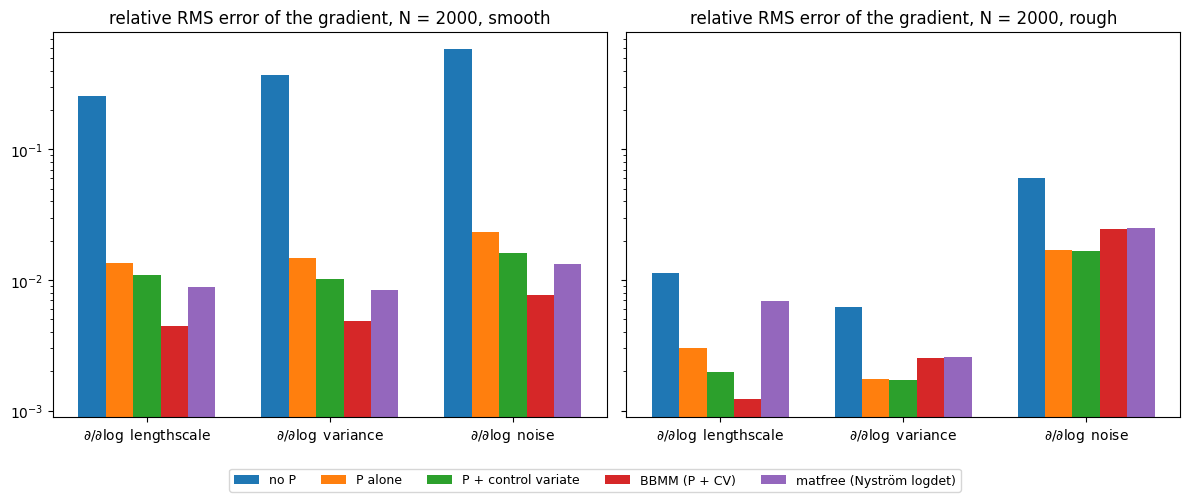

,grad_rel_rms_lengthscale,grad_rel_rms_variance,grad_rel_rms_noise,t_grad_s,passes_grad
id,,,,,
gaussian-smooth-2000-cg,0.257889,0.370492,0.585400,11.236667,671.0
gaussian-smooth-2000-cg-nystrom-fixedP,0.013526,0.014736,0.023283,8.314292,46.0
gaussian-smooth-2000-cg-nystrom,0.010967,0.010164,0.016060,9.571566,49.0
gaussian-smooth-2000-bbmm,0.004454,0.004833,0.007637,2.554227,55.0
gaussian-smooth-2000-matfree,0.008926,0.008443,0.013340,5.224063,48.0
gaussian-rough-2000-cg,0.011402,0.006220,0.060652,8.342581,405.0
gaussian-rough-2000-cg-nystrom-fixedP,0.003004,0.001736,0.016924,12.351970,286.0
gaussian-rough-2000-cg-nystrom,0.001983,0.001715,0.016718,13.471075,290.0
gaussian-rough-2000-bbmm,0.001230,0.002536,0.024721,12.272929,432.0


In [12]:
grad_configs = ["cg", "cg-nystrom-fixedP", "cg-nystrom", "bbmm", "matfree"]
grad_labels = [
    "no P",
    "P alone",
    "P + control variate",
    "BBMM (P + CV)",
    "matfree (Nyström logdet)",
]
hyper = ["lengthscale", "variance", "noise"]
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
for ax, kernel_name in zip(axes, ["smooth", "rough"]):
    width = 0.15
    for i, (config, label) in enumerate(zip(grad_configs, grad_labels)):
        row = results.loc[f"gaussian-{kernel_name}-2000-{config}"]
        values = [row[f"grad_rel_rms_{h}"] for h in hyper]
        ax.bar(
            np.arange(3) + (i - 2) * width, values, width, color=f"C{i}", label=label
        )
    ax.set_xticks(np.arange(3), [rf"$\partial / \partial \log$ {h}" for h in hyper])
    ax.set_yscale("log")
    ax.set_title(f"relative RMS error of the gradient, N = 2000, {kernel_name}")
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=5, fontsize=9)
plt.tight_layout(rect=(0, 0.07, 1, 1))
plt.show()
cite(
    *[f"gaussian-{k}-2000-{c}" for k in ("smooth", "rough") for c in grad_configs],
    columns=(
        "grad_rel_rms_lengthscale",
        "grad_rel_rms_variance",
        "grad_rel_rms_noise",
        "t_grad_s",
        "passes_grad",
    ),
)

**The rank.** The preconditioner's rank $R$ has to cover the effective dimension. On the smooth kernel at $N = 2000$, $d_\text{eff} = 355$ (row `gaussian-smooth-2000-dense`); rank 50, 200 and 800 give an RMS evidence error of 1.08, 1.30 and 0.18 nats and a largest gradient error of 1.6, 1.3 and 0.24 %, for 2.05, 1.71 and 3.95 s per evidence (rows `gaussian-smooth-2000-matfree-r50`, `-matfree`, `-matfree-r800`). Only the rank above $2 d_\text{eff}$ moves the error. On the rough kernel $d_\text{eff} = 1778$ of 2000 (row `gaussian-rough-2000-dense`), and no rank up to 800 helps (6.6, 6.7 and 8.2 nats, rows `gaussian-rough-2000-matfree-r50`, `-matfree`, `-matfree-r800`): that kernel is a case for the dense solver. The FITC preconditioner gives the same evidence as Nyström in `matfree_solver`, whose `NystromLogdet` builds its own sketch, and costs more CG steps (79 against 55 passes on the smooth kernel, 200 against 174 on the rough one, rows `gaussian-*-2000-matfree-fitc`).

**The Lanczos order.** A preconditioner lowers the variance of the evidence but not the bias of truncated Lanczos, which the Lanczos order sets. With the same probes, 60 steps instead of 30 leave the mean evidence unchanged on the smooth kernel (a difference of 0.0 nats) and move it by 0.94 nats on the rough one at $N = 2000$ (bias 2.99 against 3.93 nats, rows `gaussian-rough-2000-matfree`, `-matfree-lanczos60`), against a standard deviation over keys of 7.3 nats. The truncation bias exists on the rough kernel, but at this size the probe noise is about eight times larger.

In [13]:
cite(
    *[
        f"gaussian-{k}-2000-{c}"
        for k in ("smooth", "rough")
        for c in (
            "matfree-r50",
            "matfree",
            "matfree-r800",
            "matfree-fitc",
            "matfree-lanczos60",
        )
    ],
    columns=(
        "rank",
        "logz_rel_rms",
        "logz_bias",
        "logz_std",
        "logz_rms",
        "grad_rel_rms_max",
        "t_evidence_s",
        "passes_evidence",
    ),
)

,rank,logz_rel_rms,logz_bias,logz_std,logz_rms,grad_rel_rms_max,t_evidence_s,passes_evidence
id,,,,,,,,
gaussian-smooth-2000-matfree-r50,50.0,0.000727,0.164976,1.302842,1.076483,0.015790,2.053326,107.0
gaussian-smooth-2000-matfree,200.0,0.000878,0.654207,1.376287,1.300294,0.013340,1.711607,55.0
gaussian-smooth-2000-matfree-r800,800.0,0.000119,-0.159208,0.093654,0.176620,0.002401,3.948382,40.0
gaussian-smooth-2000-matfree-fitc,200.0,0.000878,0.654207,1.376287,1.300294,0.013340,2.088092,79.0
gaussian-smooth-2000-matfree-lanczos60,200.0,0.000878,0.654207,1.376287,1.300294,0.013340,3.239185,85.0
gaussian-rough-2000-matfree-r50,50.0,0.009449,-1.775704,7.838125,6.641580,0.080736,3.724866,222.0
gaussian-rough-2000-matfree,200.0,0.009501,2.992423,7.312643,6.678655,0.025240,3.429882,174.0
gaussian-rough-2000-matfree-r800,800.0,0.011668,-4.684094,8.245762,8.201776,0.037230,4.924922,93.0
gaussian-rough-2000-matfree-fitc,200.0,0.009501,2.992442,7.312620,6.678647,0.025240,4.299671,200.0


## 6. Inside NUTS and SVI

A stochastic log-determinant makes the evidence a random function of the hyperparameters. With a fixed key the probes are the same at every call (common random numbers): the evidence is then a smooth, deterministic function, and an optimiser or a sampler sees a fixed approximation of the exact one. SVI and gradient-based fits want exactly that. NUTS also runs on it, but it samples the posterior of that fixed approximation, not the exact posterior, and a longer chain does not remove the difference. With a fresh key per call (`gaussx.KeyedSolver(solver, key)`; the key is a pytree leaf, so it can change under `jit` without recompiling) the error is different at every call, which a stochastic-gradient method averages out but which breaks the detailed balance of a Metropolis or NUTS step.

The cell below evaluates the log marginal at 25 lengthscales on $N = 500$ points with the `matfree` preset, once with one fixed key and once with a fresh key per lengthscale, against the dense curve.

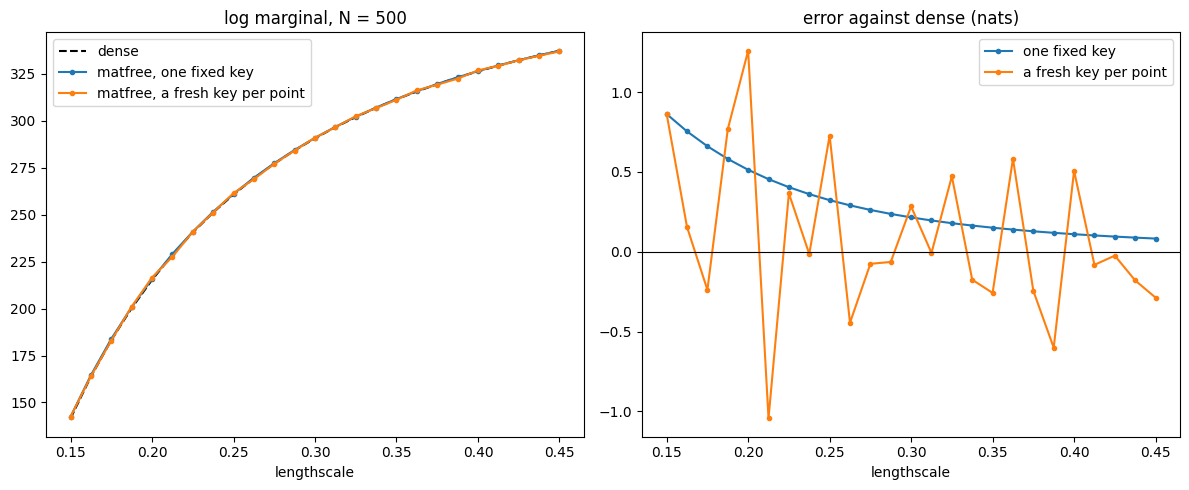

fixed key: error spread 0.779 nats; fresh keys: 2.302 nats
dense evidence range over the grid: 195.7 nats


In [14]:
X_small, y_small = X[:500], y[:500]
base = px.matfree_solver(rank=200, key=jr.key(0), throw=False)


@eqx.filter_jit
def evidence_at(log_lengthscale, solver, matrix_free):
    k = kl.Matern(nu=1.5, lengthscale=jnp.exp(log_lengthscale), variance=1.0)
    prior = px.GPPrior(k, X_small, solver=solver, matrix_free=matrix_free)
    return prior.log_marginal(y_small, jnp.asarray(NOISE_VAR))


grid = jnp.log(jnp.linspace(0.15, 0.45, 25))
exact = np.array([evidence_at(g, None, False) for g in grid])
fixed = np.array([evidence_at(g, base, True) for g in grid])
fresh = np.array(
    [evidence_at(g, gx.KeyedSolver(base, jr.key(i)), True) for i, g in enumerate(grid)]
)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
lengthscales = np.exp(np.asarray(grid))
axes[0].plot(lengthscales, exact, "k--", label="dense")
axes[0].plot(
    lengthscales, fixed, "C0", marker="o", ms=3, label="matfree, one fixed key"
)
axes[0].plot(
    lengthscales, fresh, "C1", marker="o", ms=3, label="matfree, a fresh key per point"
)
axes[0].set_xlabel("lengthscale")
axes[0].set_title("log marginal, N = 500")
axes[0].legend()
axes[1].plot(lengthscales, fixed - exact, "C0", marker="o", ms=3, label="one fixed key")
axes[1].plot(
    lengthscales, fresh - exact, "C1", marker="o", ms=3, label="a fresh key per point"
)
axes[1].axhline(0.0, color="k", lw=0.8)
axes[1].set_xlabel("lengthscale")
axes[1].set_title("error against dense (nats)")
axes[1].legend()
plt.tight_layout()
plt.show()
print(
    f"fixed key: error spread {np.ptp(fixed - exact):.3f} nats; fresh keys: {np.ptp(fresh - exact):.3f} nats"
)
print(f"dense evidence range over the grid: {np.ptp(exact):.1f} nats")

To see whether the noise matters, compare the spread of the error over keys with the differences of the evidence that the fit or the sampler has to resolve. Above, the dense evidence moves by many nats across the grid, while the fixed-key error is a smooth offset and the fresh-key error jumps from point to point. A NUTS step compares log densities that differ by about one nat, so an evidence whose standard deviation over keys (`logz_std` in the saved rows) is near one nat or more changes the answer. At $N = 2000$ it is 1.4 nats for `matfree` and 0.51 nats for `bbmm` on the smooth Gaussian problem and 7.3 and 8.0 nats on the rough one (rows `gaussian-*-2000-matfree`, `gaussian-*-2000-bbmm`), while the Bernoulli Laplace evidence on the smooth kernel is at 0.012 and 0.013 nats (rows `bernoulli-smooth-2000-matfree`, `-bbmm`). For NUTS, then, use the exact solver where it fits, and otherwise a fixed key with a rank high enough that `logz_std` is well below one nat, checked with a few keys as this benchmark does. Inside a NumPyro model a fixed key is the preset's own `key`; a fresh key per step, for SVI, is a `KeyedSolver` around it:

```python
import numpyro
import numpyro.distributions as dist

base = px.matfree_solver(rank=800, key=jr.key(0))  # fixed key: one fixed approximation


def model(X, y):
    lengthscale = numpyro.sample("lengthscale", dist.LogNormal(0.0, 1.0))
    kernel = kl.Matern(nu=1.5, lengthscale=lengthscale)
    # for SVI only: fresh probes at every step
    solver = gx.KeyedSolver(base, numpyro.prng_key())
    prior = px.GPPrior(kernel, X, solver=solver, matrix_free=True)
    px.gp_factor("y", prior, y, jnp.asarray(0.01))
```

## 7. When not to

**Exact below a few thousand, and here up to 8000.** On the measured CPU the dense solver gives the exact evidence faster than any iterative one at every size up to $N = 8000$, and its gradient as fast as `bbmm`'s at 8000 (the rows printed below). Switch when the dense factor and its gradient no longer fit: their temporaries were 977 MB and 4.9 GB at $N = 8000$ (row `gaussian-smooth-8000-dense`) and grew 18-fold from $N = 2000$ to $N = 8000$ (rows `gaussian-smooth-2000-dense`, `gaussian-smooth-8000-dense`). No GPU was measured, since the VM has none.

**Rough kernels.** When $d_\text{eff}$ is close to $N$, no low-rank preconditioner captures $\mathbf{K}_{XX}$, and the stochastic log-determinant stays several nats off at every rank tried (section 5). Use the dense solver while it fits; beyond, an approximation that does not need a low-rank $\mathbf{K}_{XX}$ to be accurate, such as inducing points (`SparseGPPrior`) or, on a time axis, a Markov GP (`pyrox_ssm.MarkovGPPrior`). Those were not part of this benchmark.

**Sparse, Markov and structured kernels.** A Markov GP on a 1-D time grid runs a Kalman filter in $O(N)$, and kernels with grid or Kronecker structure have exact structured solves in gaussx. This page measures only the unstructured exact GP, so it does not compare them.

In [15]:
cite(
    *[
        row
        for k in ("smooth", "rough")
        for n in (500, 2000, 8000)
        for c in ("dense", "matfree", "bbmm")
        if (row := f"gaussian-{k}-{n}-{c}") in results.index
    ],
    columns=(
        "t_evidence_s",
        "t_grad_s",
        "mem_evidence_mb",
        "mem_grad_mb",
        "logz_rel_rms",
    ),
)

,t_evidence_s,t_grad_s,mem_evidence_mb,mem_grad_mb,logz_rel_rms
id,,,,,
gaussian-smooth-500-dense,0.008672,0.069202,3.822403,17.170181,0.000000
gaussian-smooth-500-matfree,0.283603,0.818765,16.383362,278.635536,0.002295
gaussian-smooth-500-bbmm,0.413299,0.530817,14.976562,34.846375,0.001156
gaussian-smooth-2000-dense,0.127175,1.223898,61.065689,274.673721,0.000000
gaussian-smooth-2000-matfree,1.711607,5.224063,79.846992,1027.604713,0.000878
gaussian-smooth-2000-bbmm,1.987819,2.554227,74.699532,113.445747,0.000529
gaussian-smooth-8000-dense,3.642571,47.690783,976.745682,4882.873734,0.000000
gaussian-smooth-8000-matfree,25.027743,88.732183,675.809517,4370.463844,0.000310
gaussian-smooth-8000-bbmm,40.723622,48.283848,652.580391,742.487617,0.000398


## Summary

- Up to $N = 8000$ on a CPU, keep the default `DenseSolver`: it was the fastest evidence at every size and level with `bbmm` on the gradient at 8000 (rows `gaussian-smooth-8000-*`).
- Beyond that, on a smooth kernel, `bbmm_solver` gave the cheapest gradient and the least memory of the presets, and `matfree_solver` the cheaper single evidence; both are accurate to $3 \cdot 10^{-4}$ to $4 \cdot 10^{-4}$ relative at $N = 8000$ (rows `gaussian-smooth-8000-matfree`, `-bbmm`).
- Set the rank from $d_\text{eff}$, not from $N$: rank 800 at $d_\text{eff} = 355$ cut the evidence error from 1.3 to 0.18 nats, and no rank up to 800 helped at $d_\text{eff} = 1778$ (rows `gaussian-*-2000-matfree-r800`).
- The Laplace evidence of a Bernoulli GP is far easier, 0.010 nats with either preset at $N = 2000$ on the smooth kernel (rows `bernoulli-smooth-2000-*`).
- Under NUTS, compare `logz_std` with one nat before trusting a stochastic evidence; with a fixed key the chain targets a fixed approximation of the posterior.
- The defaults of the presets (rank 200, 50 probes, 30 or 100 Lanczos steps) are left as they are: no single rank was better across the problems measured, since the rank that works follows $d_\text{eff}$.